# 02 Turning points and market-wide rises

**Data:** chosen in `common.py` (`USE_FAKE_DATA`). Chart titles say whether it is real or fake.

Two questions from section 4 of the outline:

1. **Turning points:** what does the model say when a trend is about to turn?
2. **Market-wide vs. style rises:** when a style rises, is it the style, or are searches rising for everything?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from common import load_predictions, RISING_THRESHOLD, DATA_LABEL

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
HORIZON = 4

df = load_predictions()
df = df[df["horizon"] == HORIZON].copy()
df["said_rising"] = df["predicted_growth"] > RISING_THRESHOLD
df["rose"] = df["actual_growth"] > RISING_THRESHOLD

# recent_jump (last 4 weeks vs. the 4 weeks before) comes from common.py
df = df.dropna(subset=["recent_jump"])
print(f"{len(df):,} forecasts, {HORIZON} weeks ahead")

77,966 forecasts, 4 weeks ahead


## 1. Turning points

Each forecast week is put in one situation, using the last 4 weeks (recent jump) and the next 4 weeks (actual growth):

| Situation | Last 4 weeks | Next 4 weeks | Right answer |
| --- | --- | --- | --- |
| Rise continues | up (above threshold) | up (above threshold) | rising |
| Peak | up (above threshold) | down (below 1.0) | not rising |
| Start of a rise | flat or down (1.0 or below) | up (above threshold) | rising |
| Other | anything else | | |

For each situation, the table shows how often each model said "rising".

In [2]:
went_up = df["recent_jump"] > RISING_THRESHOLD
flat_or_down = df["recent_jump"] <= 1.0
df["situation"] = "Other"
df.loc[went_up & df["rose"], "situation"] = "Rise continues"
df.loc[went_up & (df["actual_growth"] < 1.0), "situation"] = "Peak"
df.loc[flat_or_down & df["rose"], "situation"] = "Start of a rise"

turns = (df[df["model"].isin(["lightgbm", "last_value"])]
           .groupby(["situation", "model"])["said_rising"]
           .agg(forecasts="size", said_rising_pct="mean")
           .unstack("model"))
turns[("said_rising_pct", "lightgbm")] *= 100
turns[("said_rising_pct", "last_value")] *= 100
turns.round(1).loc[["Rise continues", "Peak", "Start of a rise", "Other"]]

forecasts          said_rising_pct         
model           last_value lightgbm      last_value lightgbm
situation                                                   
Rise continues         703      703            46.8     44.5
Peak                   955      955            15.7      7.6
Start of a rise        970      970            14.5     22.1
Other                 8510     8510             3.7     11.5

**How to read it:** at a **Peak** the ideal is 0% (every "rising" there is a costly false alert). At a **Start of a rise** the ideal is 100% (every "not rising" there is a missed trend).

## 2. Market-wide vs. style rises

**Market growth** = all styles' actual 4-week averages added up ÷ all their last 4-week averages added up, per week.

A real rise counts as **market-wide** when the style did not beat the market by the threshold: style growth ÷ market growth is at or below the threshold. Otherwise it is a **style rise**.

In [3]:
main = df[df["model"] == "lightgbm"].copy()

totals = main.groupby("origin")[["actual", "last4_avg"]].sum()
market_growth = (totals["actual"] / totals["last4_avg"]).rename("market_growth")
main = main.join(market_growth, on="origin")
main["beats_market"] = main["actual_growth"] / main["market_growth"] > RISING_THRESHOLD

rises = main[main["rose"]]
kind = rises["beats_market"].map({True: "Style rise", False: "Market-wide rise"})
pd.DataFrame({"real rises": kind.value_counts(),
              "share (%)": (100 * kind.value_counts(normalize=True)).round(1)}).rename_axis("kind of rise")

,real rises,share (%)
kind of rise,,
Market-wide rise,1242,53.1
Style rise,1096,46.9


### When are rises market-wide?

Share of real rises in each month that were market-wide. The shaded area is the spring 2026 spike period.

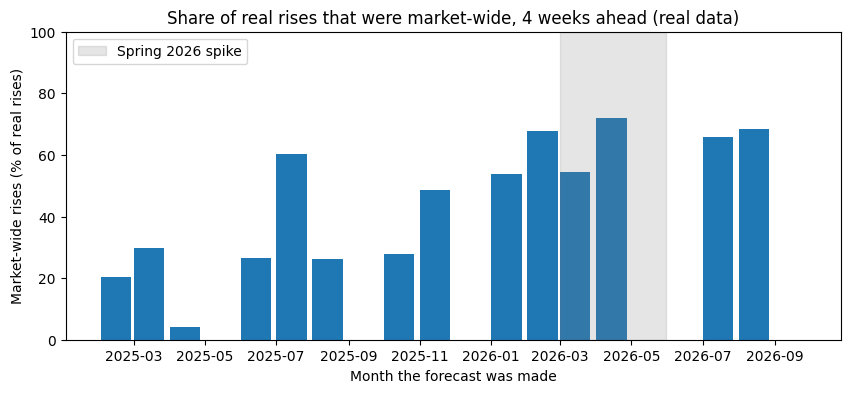

In [4]:
rises = rises.assign(month=rises["origin"].dt.to_period("M").dt.to_timestamp(),
                     market_wide=~rises["beats_market"])
monthly = 100 * rises.groupby("month")["market_wide"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly.index, monthly.values, width=26, align="edge")
ax.axvspan(pd.Timestamp("2026-03-01"), pd.Timestamp("2026-05-31"), color="grey", alpha=0.2, label="Spring 2026 spike")
ax.set_title(f"Share of real rises that were market-wide, {HORIZON} weeks ahead ({DATA_LABEL})")
ax.set_xlabel("Month the forecast was made")
ax.set_ylabel("Market-wide rises (% of real rises)")
ax.set_ylim(0, 100)
ax.legend()
fig.savefig(FIGURES / "02_market_wide_rises_by_month.png", dpi=200, bbox_inches="tight")
plt.show()

### Do the model's correct alerts pick out styles, or just the market?

Of the model's correct alerts, how many were style rises?

In [5]:
correct_alerts = main[main["said_rising"] & main["rose"]]
picked = correct_alerts["beats_market"].map({True: "Style rise", False: "Market-wide rise"})
pd.DataFrame({"correct alerts": picked.value_counts(),
              "share (%)": (100 * picked.value_counts(normalize=True)).round(1)}).rename_axis("kind of rise")

,correct alerts,share (%)
kind of rise,,
Style rise,426,62.1
Market-wide rise,260,37.9


## What this shows (will be filled once the real results are in)

1. At peaks, the model said "rising" __% of the time vs. __% for last value:
2. At the start of a rise, it caught __% vs. __%:
3. __% of real rises were market-wide, mostly in:
4. __% of correct alerts were style rises, so: